/tmp/ipykernel_1038/2108138103.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1038/2108138103.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Chips", "Mayonnaise", "Salad Dressing"])


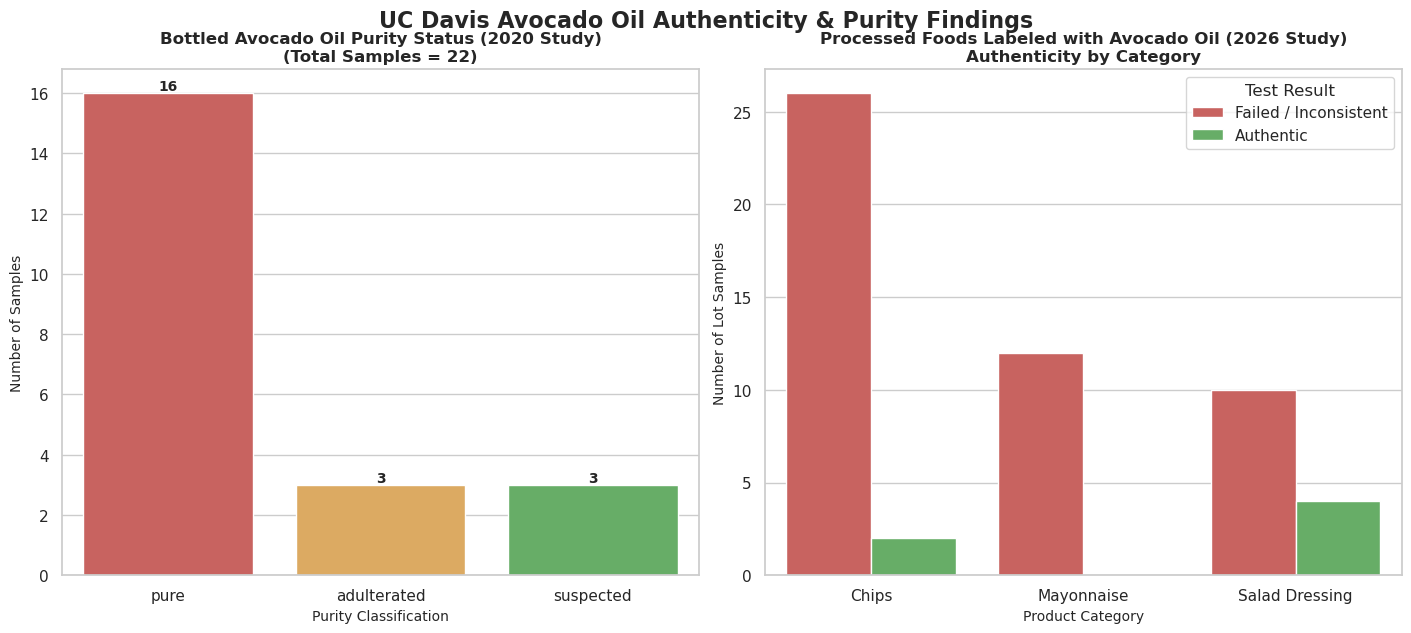

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the TidyTuesday datasets directly from GitHub
url_bottles = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-10-06/avocado_oil_bottles.csv"
url_processed = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-10-06/avocado_oil_processed_foods.csv"

avocado_oil_bottles = pd.read_csv(url_bottles)
avocado_oil_processed_foods = pd.read_csv(url_processed)

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# ---------------------------------------------------------
# Chart 1: Bottled Avocado Oil Purity & Oxidation (2020 Study)
# ---------------------------------------------------------
# Group by purity status to show the breakdown of the 22 bottles
purity_counts = (
    avocado_oil_bottles["purity_result"].value_counts().reset_index()
)
purity_counts.columns = ["purity_result", "count"]

sns.barplot(
    data=purity_counts,
    x="purity_result",
    y="count",
    palette=["#d9534f", "#f0ad4e", "#5cb85c"],
    ax=axes[0],
)
axes[0].set_title(
    "Bottled Avocado Oil Purity Status (2020 Study)\n(Total Samples = 22)",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Purity Classification", fontsize=10)
axes[0].set_ylabel("Number of Samples", fontsize=10)

# Annotate bars with counts
for p in axes[0].patches:
  height = p.get_height()
  if height > 0:
    axes[0].annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# ---------------------------------------------------------
# Chart 2: Processed Foods Authenticity by Category (2026 Study)
# ---------------------------------------------------------
# Filter for avocado oil products and calculate failure rates (authentic == False)
processed_avocado = avocado_oil_processed_foods[
    avocado_oil_processed_foods["oil_type"] == "avocado"
].copy()

# Map boolean 'authentic' to a descriptive string for plotting
processed_avocado["Authenticity Status"] = processed_avocado["authentic"].map({
    True: "Authentic",
    False: "Failed / Inconsistent",
})

# Create a grouped count plot across product categories
sns.countplot(
    data=processed_avocado,
    x="category",
    hue="Authenticity Status",
    palette={"Authentic": "#5cb85c", "Failed / Inconsistent": "#d9534f"},
    ax=axes[1],
)
axes[1].set_title(
    "Processed Foods Labeled with Avocado Oil (2026 Study)\nAuthenticity"
    " by Category",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Product Category", fontsize=10)
axes[1].set_ylabel("Number of Lot Samples", fontsize=10)
axes[1].legend(title="Test Result")

# Clean up category names on x-axis
axes[1].set_xticklabels(["Chips", "Mayonnaise", "Salad Dressing"])

# Overall Title for the Figure
fig.suptitle(
    "UC Davis Avocado Oil Authenticity & Purity Findings",
    fontsize=16,
    fontweight="bold",
    y=1.03,
)

# Show the plot
plt.show()